# 4DGS-JEPA — Experiment 3 v2: Hybrid Correspondence Stress Test

This notebook evaluates the Gaussian correspondence / identity mechanism **independently of the learned transition**. There are no learned parameters and no training epochs.

It compares:

1. **Index matching** — assumes the same array position denotes the same primitive;
2. **OT only** — entropically regularized optimal transport over the complete source and target sets;
3. **Hybrid** — clamps valid persistent canonical identities first and applies residual OT only to unmatched / ambiguous mass.

Controlled perturbations include permutation, split, merge, death, reserved-slot birth, and mixed events. Because the perturbations are synthetic, exact source--target lineage is known.

### v2 corrections and robustness additions

This revision makes the comparison fairer and more diagnostic:

- **count-aware augmented OT**: every real primitive has unit mass; the source and target dustbins receive capacities equal to the opposite set cardinality;
- hard persistent matches and residual OT therefore use the **same unit-mass scale**;
- no fixed `dustbin_mass` hyperparameter is used;
- birth and death precision / recall / F1 are reported **separately**, with N/A (`NaN`) when that event type is absent;
- the main event score is a NaN-aware macro average of applicable birth/death F1 values;
- **3 independent seeds × 50 trials** per perturbation/severity;
- modest target-side semantic noise (`sigma_sem=0.05`) avoids perfectly invariant semantic fingerprints;
- an additional **persistent-ID dropout** stress test checks that Hybrid falls back toward OT when reliable identities are hidden;
- bootstrap 95% confidence intervals are saved alongside seed-level mean ± std summaries.

The principal outputs are `paper_table_mean_std.csv`, `paper_table_bootstrap_ci.csv`,
`summary_mean_std.csv`, `birth_death_detailed.csv`, severity plots, and ID-dropout plots.


In [1]:
# ---------- Colab-friendly setup ----------
import os, math, json, random, shutil
from pathlib import Path
from dataclasses import dataclass, asdict
from typing import Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def seed_all(seed: int):
    random.seed(seed)
    np.random.seed(seed)

BASE_DIR = Path('/content') if Path('/content').exists() else Path.cwd()
RESULT_DIR = BASE_DIR / '4dgs_jepa_exp3_results_v2'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print('Exp3 uses NumPy/SciPy only; no model training or GPU is required.')
print('Results directory:', RESULT_DIR)


Exp3 uses NumPy/SciPy only; no model training or GPU is required.
Results directory: /content/4dgs_jepa_exp3_results_v2


In [2]:
# ---------- Configuration ----------
@dataclass
class Config:
    active_primitives: int = 24
    reserve_slots: int = 6
    num_groups: int = 4
    semantic_dim: int = 6

    # Statistical replication
    seeds: Tuple[int, ...] = (0, 1, 2)
    trials_per_setting: int = 50
    severities: Tuple[float, ...] = (0.10, 0.25, 0.40)

    # Entropic OT
    sinkhorn_eps: float = 0.08
    sinkhorn_iters: int = 200
    sinkhorn_tol: float = 1e-7
    dustbin_cost: float = 1.20

    # Perturbation noise
    position_noise_std: float = 0.025
    logscale_noise_std: float = 0.020
    semantic_noise_std: float = 0.050

    # Persistent-ID dropout appendix stress test
    id_dropout_rates: Tuple[float, ...] = (0.0, 0.10, 0.25, 0.50)
    id_dropout_kind: str = 'mixed'
    id_dropout_severity: float = 0.25

    # Reporting
    bootstrap_samples: int = 2000
    bootstrap_seed: int = 12345

CFG = Config()
print(CFG)

with open(RESULT_DIR / 'config.json', 'w') as f:
    json.dump(asdict(CFG), f, indent=2)


Config(active_primitives=24, reserve_slots=6, num_groups=4, semantic_dim=6, seeds=(0, 1, 2), trials_per_setting=50, severities=(0.1, 0.25, 0.4), sinkhorn_eps=0.08, sinkhorn_iters=200, sinkhorn_tol=1e-07, dustbin_cost=1.2, position_noise_std=0.025, logscale_noise_std=0.02, semantic_noise_std=0.05, id_dropout_rates=(0.0, 0.1, 0.25, 0.5), id_dropout_kind='mixed', id_dropout_severity=0.25, bootstrap_samples=2000, bootstrap_seed=12345)


In [3]:
# ---------- Data structures / source generation ----------
def unit(x):
    x = np.asarray(x, dtype=np.float64)
    return x / (np.linalg.norm(x, axis=-1, keepdims=True) + 1e-12)

def make_source(seed, cfg):
    rng = np.random.default_rng(seed)
    N = cfg.active_primitives + cfg.reserve_slots

    gids = np.repeat(np.arange(cfg.num_groups), math.ceil(N / cfg.num_groups))[:N]
    centers = rng.uniform(-1, 1, (cfg.num_groups, 3))

    mu = np.vstack([
        centers[g] + rng.normal(0, 0.18, 3)
        for g in gids
    ]).astype(np.float64)

    logscale = rng.uniform(
        np.log(0.04), np.log(0.12), (N, 3)
    ).astype(np.float64)

    sem = unit(rng.normal(size=(N, cfg.semantic_dim))).astype(np.float64)

    active = np.zeros(N, dtype=bool)
    active[:cfg.active_primitives] = True

    # Reserved slots are inactive but spatially anchored near their motion groups.
    for i in range(cfg.active_primitives, N):
        mu[i] = centers[gids[i]] + rng.normal(0, 0.08, 3)

    return {
        'mu': mu,
        'logscale': logscale,
        'sem': sem,
        'group': gids.astype(int),
        'active': active,
        'slot_id': np.arange(N, dtype=int),
    }

def copy_item(src, i):
    return {
        'mu': src['mu'][i].copy(),
        'logscale': src['logscale'][i].copy(),
        'sem': src['sem'][i].copy(),
        'group': int(src['group'][i]),
        'slot_id': int(src['slot_id'][i]),
        'lineage': {int(src['slot_id'][i])},
        'birth': not bool(src['active'][i]),
    }

def copy_target(tgt):
    out = {}
    for k, v in tgt.items():
        if isinstance(v, np.ndarray):
            out[k] = v.copy()
        elif k == 'lineage':
            out[k] = [set(x) for x in v]
        else:
            out[k] = v
    return out


In [4]:
# ---------- Perturbation generator ----------
def perturb_source(src, kind, severity, rng, cfg):
    active_ids = np.flatnonzero(src['active']).tolist()
    reserve_ids = np.flatnonzero(~src['active']).tolist()

    items = [copy_item(src, i) for i in active_ids]

    # Small physical motion before the identity/topology perturbation.
    for x in items:
        x['mu'] += rng.normal(0, cfg.position_noise_std, 3)
        x['logscale'] += rng.normal(0, cfg.logscale_noise_std, 3)

    n = max(1, int(round(severity * len(active_ids))))

    if kind in ('split', 'mixed'):
        candidates = rng.choice(
            len(items), size=min(n, len(items)), replace=False
        ).tolist()

        new_items = []
        for idx in sorted(candidates, reverse=True):
            parent = items.pop(idx)
            # Children have no valid one-to-one persistent ID, but retain
            # the parent's ground-truth lineage for evaluation.
            for sign in (-1, 1):
                child = {
                    k: (
                        v.copy() if isinstance(v, np.ndarray)
                        else set(v) if isinstance(v, set)
                        else v
                    )
                    for k, v in parent.items()
                }
                child['mu'] = parent['mu'] + sign * rng.normal(0.035, 0.008, 3)
                child['slot_id'] = -1
                child['birth'] = False
                new_items.append(child)
        items.extend(new_items)

    if kind in ('merge', 'mixed') and len(items) >= 2:
        # Merge nearby compatible primitives within the same motion group.
        k = min(n, max(1, len(items) // 4))
        for _ in range(k):
            pairs = [
                (i, j)
                for i in range(len(items))
                for j in range(i + 1, len(items))
                if items[i]['group'] == items[j]['group']
            ]
            if not pairs:
                break

            i, j = min(
                pairs,
                key=lambda ij: np.linalg.norm(
                    items[ij[0]]['mu'] - items[ij[1]]['mu']
                ),
            )
            a, b = items[i], items[j]
            merged = {
                'mu': 0.5 * (a['mu'] + b['mu']),
                'logscale': 0.5 * (a['logscale'] + b['logscale']),
                'sem': unit((a['sem'] + b['sem'])[None])[0],
                'group': a['group'],
                'slot_id': -1,
                'lineage': set(a['lineage']) | set(b['lineage']),
                'birth': False,
            }
            for idx in sorted((i, j), reverse=True):
                items.pop(idx)
            items.append(merged)

    if kind in ('death', 'mixed') and items:
        k = min(n, len(items) // 3 if len(items) >= 3 else 1)
        if k > 0:
            remove = set(
                rng.choice(len(items), size=k, replace=False).tolist()
            )
            items = [
                x for idx, x in enumerate(items)
                if idx not in remove
            ]

    if kind in ('birth', 'mixed') and reserve_ids:
        k = min(n, len(reserve_ids))
        chosen = rng.choice(reserve_ids, size=k, replace=False)
        for rid in chosen:
            x = copy_item(src, int(rid))
            x['birth'] = True
            x['mu'] += rng.normal(0, 0.04, 3)
            x['logscale'] += rng.normal(0, cfg.logscale_noise_std, 3)
            items.append(x)

    # Add modest target-side semantic noise so semantics are informative
    # without acting as a perfectly invariant identity fingerprint.
    if cfg.semantic_noise_std > 0:
        for x in items:
            x['sem'] = unit(
                (x['sem'] + rng.normal(
                    0, cfg.semantic_noise_std, cfg.semantic_dim
                ))[None]
            )[0]

    # Permutation and mixed conditions explicitly destroy array-order identity.
    if kind in ('permutation', 'mixed'):
        rng.shuffle(items)

    tgt = {
        k: []
        for k in [
            'mu', 'logscale', 'sem', 'group',
            'slot_id', 'lineage', 'birth'
        ]
    }
    for x in items:
        for k in tgt:
            tgt[k].append(x[k])

    for k in ['mu', 'logscale', 'sem']:
        tgt[k] = np.asarray(tgt[k], dtype=np.float64)
    tgt['group'] = np.asarray(tgt['group'], dtype=int)
    tgt['slot_id'] = np.asarray(tgt['slot_id'], dtype=int)
    tgt['birth'] = np.asarray(tgt['birth'], dtype=bool)

    return tgt

def hide_persistent_ids(tgt, dropout_rate, rng):
    """Hide a fraction of otherwise valid target-side persistent IDs.

    Geometry and ground-truth lineage remain unchanged. Only the identity
    information available to the Hybrid matcher is removed.
    """
    out = copy_target(tgt)
    valid = np.flatnonzero(out['slot_id'] >= 0)

    k = int(round(float(dropout_rate) * len(valid)))
    if k > 0:
        chosen = rng.choice(valid, size=min(k, len(valid)), replace=False)
        out['slot_id'][chosen] = -1

    return out


In [5]:
# ---------- Entropic OT with count-aware dustbins ----------
def pair_cost(src, tgt, cfg):
    """Geometry + covariance shape + semantics + motion-group compatibility."""
    dm = (
        (src['mu'][:, None, :] - tgt['mu'][None, :, :]) ** 2
    ).sum(-1)
    ds = (
        (src['logscale'][:, None, :] - tgt['logscale'][None, :, :]) ** 2
    ).sum(-1)
    cos = 1 - np.clip(src['sem'] @ tgt['sem'].T, -1, 1)
    gp = (
        src['group'][:, None] != tgt['group'][None, :]
    ).astype(float)

    return 2.0 * dm + 0.25 * ds + 0.8 * cos + 0.8 * gp

def sinkhorn_balanced(C, p, q, eps, iters, tol=1e-7):
    """Balanced Sinkhorn scaling for positive marginals of equal total mass.

    The dustbin entries guarantee a non-negligible kernel path for every
    row/column in this controlled benchmark, so direct-domain scaling is
    both stable here and substantially faster than repeated log-sum-exp.
    """
    p = np.asarray(p, dtype=np.float64)
    q = np.asarray(q, dtype=np.float64)

    if not np.isclose(p.sum(), q.sum()):
        raise ValueError(f'Unequal OT mass: p={p.sum()} q={q.sum()}')
    if np.any(p <= 0) or np.any(q <= 0):
        raise ValueError('All Sinkhorn marginals must be strictly positive.')

    K = np.exp(-np.asarray(C, dtype=np.float64) / eps)
    K = np.maximum(K, 1e-300)

    u = np.ones_like(p)
    v = np.ones_like(q)

    for it in range(iters):
        u = p / (K @ v + 1e-300)
        v = q / (K.T @ u + 1e-300)

        if (it + 1) % 25 == 0 or it == iters - 1:
            P = (u[:, None] * K) * v[None, :]
            err = max(
                np.max(np.abs(P.sum(axis=1) - p)),
                np.max(np.abs(P.sum(axis=0) - q)),
            )
            if err < tol:
                break

    return (u[:, None] * K) * v[None, :]

def _subset_dict(d, idx, full_len):
    return {
        k: (
            v[idx]
            if isinstance(v, np.ndarray) and len(v) == full_len
            else v
        )
        for k, v in d.items()
    }

def ot_plan(src, tgt, cfg, src_mask=None, tgt_mask=None):
    """Count-aware augmented OT.

    Each real source and each real target has unit mass. For ns residual
    sources and nt residual targets, augmented marginals are

        p = [1,...,1, nt]
        q = [1,...,1, ns],

    so both sides have total mass ns + nt. The final row / column are
    source / target dustbins. This gives enough dustbin capacity for
    arbitrary cardinality mismatch and puts OT mass on the same scale as
    unit persistent matches.
    """
    si = (
        np.arange(len(src['mu']))
        if src_mask is None
        else np.flatnonzero(src_mask)
    )
    tj = (
        np.arange(len(tgt['mu']))
        if tgt_mask is None
        else np.flatnonzero(tgt_mask)
    )
    ns, nt = len(si), len(tj)

    Pfull = np.zeros(
        (len(src['mu']) + 1, len(tgt['mu']) + 1),
        dtype=np.float64,
    )

    if ns == 0 and nt == 0:
        return Pfull

    # Exact count-aware edge cases: each unmatched real primitive carries
    # one unit of mass directly to/from the corresponding dustbin.
    if ns == 0:
        Pfull[-1, tj] = 1.0
        return Pfull
    if nt == 0:
        Pfull[si, -1] = 1.0
        return Pfull

    src_sub = _subset_dict(src, si, len(src['mu']))
    tgt_sub = _subset_dict(tgt, tj, len(tgt['mu']))
    C = pair_cost(src_sub, tgt_sub, cfg)

    Ca = np.full(
        (ns + 1, nt + 1),
        cfg.dustbin_cost,
        dtype=np.float64,
    )
    Ca[:ns, :nt] = C
    Ca[-1, -1] = 0.0

    # Count-aware dustbin capacities.
    p = np.r_[np.ones(ns), float(nt)]
    q = np.r_[np.ones(nt), float(ns)]

    P = sinkhorn_balanced(
        Ca, p, q,
        cfg.sinkhorn_eps,
        cfg.sinkhorn_iters,
        cfg.sinkhorn_tol,
    )

    Pfull[
        np.ix_(
            np.r_[si, len(src['mu'])],
            np.r_[tj, len(tgt['mu'])],
        )
    ] = P

    return Pfull

def index_plan(src, tgt):
    """Naive array-index matching baseline with unit mass."""
    ns, nt = len(src['mu']), len(tgt['mu'])
    P = np.zeros((ns + 1, nt + 1), dtype=np.float64)
    k = min(ns, nt)

    for i in range(k):
        P[i, i] = 1.0
    for i in range(k, ns):
        P[i, -1] = 1.0
    for j in range(k, nt):
        P[-1, j] = 1.0

    return P

def hybrid_plan(src, tgt, cfg):
    """Clamp valid one-to-one persistent IDs; OT-match only residual mass."""
    ns, nt = len(src['mu']), len(tgt['mu'])
    P = np.zeros((ns + 1, nt + 1), dtype=np.float64)

    used_s = np.zeros(ns, dtype=bool)
    used_t = np.zeros(nt, dtype=bool)

    slot_to_src = {int(s): i for i, s in enumerate(src['slot_id'])}

    # Only unique, valid target IDs are eligible for hard clamping.
    # Split / merge targets use slot_id=-1 and therefore go to residual OT.
    counts = {}
    for sid in tgt['slot_id']:
        if sid >= 0:
            counts[int(sid)] = counts.get(int(sid), 0) + 1

    for j, sid in enumerate(tgt['slot_id']):
        sid = int(sid)
        if (
            sid >= 0
            and sid in slot_to_src
            and counts.get(sid, 0) == 1
        ):
            i = slot_to_src[sid]
            if not used_s[i]:
                P[i, j] = 1.0
                used_s[i] = True
                used_t[j] = True

    # Residual OT also uses unit mass per unmatched primitive, so hard
    # persistent matches and soft residual matches have the same scale.
    P += ot_plan(src, tgt, cfg, ~used_s, ~used_t)
    return P


In [6]:
# ---------- Metrics ----------
def lineage_matrix(src, tgt):
    ns, nt = len(src['mu']), len(tgt['mu'])
    Y = np.zeros((ns, nt), dtype=np.float64)

    for i, sid in enumerate(src['slot_id']):
        for j, lineage in enumerate(tgt['lineage']):
            Y[i, j] = float(int(sid) in lineage)

    return Y

def binary_prf(gt, pred):
    """Precision/recall/F1, with NaN when the event type is absent in GT."""
    gt = np.asarray(gt, dtype=bool)
    pred = np.asarray(pred, dtype=bool)

    n_pos = int(gt.sum())
    if n_pos == 0:
        return np.nan, np.nan, np.nan, 0

    tp = int(np.sum(gt & pred))
    fp = int(np.sum(~gt & pred))
    fn = int(np.sum(gt & ~pred))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )
    return precision, recall, f1, n_pos

def event_metrics(src, tgt, P):
    ns, nt = len(src['mu']), len(tgt['mu'])

    # ----- Death -----
    # GT death: an active source slot is absent from all target lineages.
    all_lineage = (
        set().union(*tgt['lineage'])
        if len(tgt['lineage'])
        else set()
    )
    gt_death = np.array([
        bool(src['active'][i])
        and int(src['slot_id'][i]) not in all_lineage
        for i in range(ns)
    ])

    # With unit source marginals, compare mass sent to the target dustbin
    # with total mass sent to real targets.
    pred_death = np.array([
        P[i, -1] >= P[i, :nt].sum()
        for i in range(ns)
    ]) & src['active']

    dp, dr, df1, nd = binary_prf(gt_death, pred_death)

    # ----- Birth -----
    # GT birth: a target descends from an inactive reserved canonical slot.
    inactive_ids = set(src['slot_id'][~src['active']].tolist())
    gt_birth = np.array([
        len(lineage & inactive_ids) > 0
        for lineage in tgt['lineage']
    ])

    active_idx = np.flatnonzero(src['active'])
    reserve_idx = np.flatnonzero(~src['active'])

    pred_birth = []
    for j in range(nt):
        active_mass = (
            P[active_idx, j].sum()
            if len(active_idx)
            else 0.0
        )
        reserve_mass = (
            P[reserve_idx, j].sum()
            if len(reserve_idx)
            else 0.0
        )
        # The source-side dustbin is a fallback signal for genuinely
        # unmatched/new target geometry.
        birth_mass = reserve_mass + P[-1, j]
        pred_birth.append(birth_mass >= active_mass)

    pred_birth = np.asarray(pred_birth, dtype=bool)
    bp, br, bf1, nb = binary_prf(gt_birth, pred_birth)

    applicable_f1 = np.asarray([bf1, df1], dtype=np.float64)
    event_f1_macro = (
        float(np.nanmean(applicable_f1))
        if np.isfinite(applicable_f1).any()
        else np.nan
    )

    return {
        'birth_precision': bp,
        'birth_recall': br,
        'birth_f1': bf1,
        'birth_gt_count': nb,
        'death_precision': dp,
        'death_recall': dr,
        'death_f1': df1,
        'death_gt_count': nd,
        'event_f1_macro': event_f1_macro,
    }

def metrics(src, tgt, P):
    ns, nt = len(src['mu']), len(tgt['mu'])
    real = P[:ns, :nt]
    Y = lineage_matrix(src, tgt)

    lineage_mass = (Y * real).sum() / (real.sum() + 1e-12)

    dist = np.linalg.norm(
        src['mu'][:, None, :] - tgt['mu'][None, :, :],
        axis=-1,
    )
    geometry_discrepancy = (
        (real * dist).sum() / (real.sum() + 1e-12)
    )

    return {
        'lineage_mass': lineage_mass,
        'geometry_discrepancy': geometry_discrepancy,
        **event_metrics(src, tgt, P),
    }


In [7]:
# ---------- Reporting helpers ----------
METHODS = ['Index', 'OT only', 'Hybrid']
KINDS = ['permutation', 'split', 'merge', 'death', 'birth', 'mixed']

CORE_METRICS = [
    'lineage_mass',
    'geometry_discrepancy',
    'birth_precision',
    'birth_recall',
    'birth_f1',
    'death_precision',
    'death_recall',
    'death_f1',
    'event_f1_macro',
]

def bootstrap_mean_ci(values, rng, n_boot=2000, alpha=0.05):
    x = np.asarray(values, dtype=np.float64)
    x = x[np.isfinite(x)]

    if len(x) == 0:
        return np.nan, np.nan, np.nan
    if len(x) == 1:
        return float(x[0]), float(x[0]), float(x[0])

    idx = rng.integers(0, len(x), size=(n_boot, len(x)))
    boot = x[idx].mean(axis=1)
    return (
        float(x.mean()),
        float(np.quantile(boot, alpha / 2)),
        float(np.quantile(boot, 1 - alpha / 2)),
    )

def seed_trial_rng(seed, severity_idx, trial, kind_idx, stream=0):
    """Deterministic independent RNG stream for reproducible paired trials."""
    ss = np.random.SeedSequence([
        int(seed),
        int(severity_idx),
        int(trial),
        int(kind_idx),
        int(stream),
    ])
    return np.random.default_rng(ss)

def source_seed(seed, severity_idx, trial):
    return int(
        100_000
        + 100_000 * int(seed)
        + 1_000 * int(severity_idx)
        + int(trial)
    )


In [8]:
# ---------- Main stress tests: 3 seeds × 50 trials ----------
rows = []

for seed in CFG.seeds:
    for severity_idx, severity in enumerate(CFG.severities):
        for trial in range(CFG.trials_per_setting):
            # Same source scene is shared across perturbation kinds for this
            # seed / severity / trial, making method comparisons paired.
            src = make_source(
                source_seed(seed, severity_idx, trial),
                CFG,
            )

            for kind_idx, kind in enumerate(KINDS):
                rng = seed_trial_rng(
                    seed, severity_idx, trial, kind_idx, stream=0
                )
                tgt = perturb_source(src, kind, severity, rng, CFG)

                plans = {
                    'Index': index_plan(src, tgt),
                    'OT only': ot_plan(src, tgt, CFG),
                    'Hybrid': hybrid_plan(src, tgt, CFG),
                }

                for method, P in plans.items():
                    m = metrics(src, tgt, P)
                    rows.append({
                        'seed': seed,
                        'severity': severity,
                        'trial': trial,
                        'kind': kind,
                        'method': method,
                        **m,
                    })

res = pd.DataFrame(rows)
res.to_csv(RESULT_DIR / 'all_trials.csv', index=False)

# First aggregate within seed, then report mean ± std across independent seeds.
summary_by_seed = (
    res.groupby(['seed', 'kind', 'severity', 'method'])[CORE_METRICS]
    .mean(numeric_only=True)
    .reset_index()
)
summary_by_seed.to_csv(RESULT_DIR / 'summary_by_seed.csv', index=False)

summary_mean_std = (
    summary_by_seed
    .groupby(['kind', 'severity', 'method'])[CORE_METRICS]
    .agg(['mean', 'std'])
    .reset_index()
)
summary_mean_std.to_csv(RESULT_DIR / 'summary_mean_std.csv', index=False)

print('Total evaluated method-trials:', len(res))
display(
    res.groupby(['kind', 'method'])[
        ['lineage_mass', 'event_f1_macro', 'geometry_discrepancy']
    ].mean()
)


Total evaluated method-trials: 8100


lineage_mass  event_f1_macro  geometry_discrepancy
kind        method                                                     
birth       Hybrid       1.000000        1.000000              0.043752
            Index        0.867111        1.000000              0.060659
            OT only      0.996677        1.000000              0.044190
death       Hybrid       1.000000        1.000000              0.039847
            Index        0.209040        0.222685              0.632914
            OT only      0.990387        1.000000              0.041965
merge       Hybrid       0.997264             NaN              0.048268
            Index        0.160584             NaN              0.829360
            OT only      0.990321             NaN              0.049999
mixed       Hybrid       0.951090        0.888446              0.064978
            Index        0.035463        0.000000              1.109772
            OT only      0.942682        0.898439              0.066379
permutation Hybrid       1.000000             NaN              0.040057
            Index        0.040556             NaN              1.053048
            OT only      0.997891             NaN              0.040425
split       Hybrid       0.977033             NaN              0.057451
            Index        0.150672             NaN              0.772922
            OT only      0.971678             NaN              0.057624

In [9]:
# ---------- Paper-table aggregates ----------
# Build seed-level aggregates so the main table can report mean ± std over 3 seeds.
paper_seed_rows = []

for seed in CFG.seeds:
    rs = res[res.seed == seed]

    for method in METHODS:
        d = rs[rs.method == method]

        perm = d.loc[d.kind == 'permutation', 'lineage_mass'].mean()

        split_merge = d.loc[
            d.kind.isin(['split', 'merge']),
            'lineage_mass',
        ].mean()

        birth_death_f1 = d.loc[
            d.kind.isin(['birth', 'death']),
            'event_f1_macro',
        ].mean()

        geom = d['geometry_discrepancy'].mean()

        paper_seed_rows.append({
            'seed': seed,
            'method': method,
            'Permutation lineage': perm,
            'Split/merge lineage': split_merge,
            'Birth/death F1': birth_death_f1,
            'Geometry discrepancy': geom,
        })

paper_by_seed = pd.DataFrame(paper_seed_rows)
paper_by_seed.to_csv(RESULT_DIR / 'paper_table_by_seed.csv', index=False)

paper_mean_std = (
    paper_by_seed
    .groupby('method')[
        [
            'Permutation lineage',
            'Split/merge lineage',
            'Birth/death F1',
            'Geometry discrepancy',
        ]
    ]
    .agg(['mean', 'std'])
    .loc[METHODS]
)
paper_mean_std.to_csv(RESULT_DIR / 'paper_table_mean_std.csv')

# Cluster-level values for bootstrap CIs. A cluster is one seed/trial pair;
# average across severities/kinds within that paired Monte Carlo replicate.
cluster_rows = []
for (seed, trial, method), d in res.groupby(['seed', 'trial', 'method']):
    cluster_rows.append({
        'seed': seed,
        'trial': trial,
        'method': method,
        'Permutation lineage': d.loc[
            d.kind == 'permutation', 'lineage_mass'
        ].mean(),
        'Split/merge lineage': d.loc[
            d.kind.isin(['split', 'merge']),
            'lineage_mass',
        ].mean(),
        'Birth/death F1': d.loc[
            d.kind.isin(['birth', 'death']),
            'event_f1_macro',
        ].mean(),
        'Geometry discrepancy': d['geometry_discrepancy'].mean(),
    })

paper_clusters = pd.DataFrame(cluster_rows)

boot_rng = np.random.default_rng(CFG.bootstrap_seed)
ci_rows = []
for method in METHODS:
    d = paper_clusters[paper_clusters.method == method]
    row = {'method': method}

    for metric in [
        'Permutation lineage',
        'Split/merge lineage',
        'Birth/death F1',
        'Geometry discrepancy',
    ]:
        mean, lo, hi = bootstrap_mean_ci(
            d[metric].values,
            boot_rng,
            CFG.bootstrap_samples,
        )
        row[f'{metric} mean'] = mean
        row[f'{metric} ci_low'] = lo
        row[f'{metric} ci_high'] = hi

    ci_rows.append(row)

paper_ci = pd.DataFrame(ci_rows).set_index('method').loc[METHODS]
paper_ci.to_csv(RESULT_DIR / 'paper_table_bootstrap_ci.csv')

# Backward-compatible simple mean table.
paper_simple = (
    paper_by_seed
    .groupby('method')[
        [
            'Permutation lineage',
            'Split/merge lineage',
            'Birth/death F1',
            'Geometry discrepancy',
        ]
    ]
    .mean()
    .loc[METHODS]
)
paper_simple.to_csv(RESULT_DIR / 'paper_table.csv')

print('Paper table: mean ± std across the 3 independent seeds')
display(paper_mean_std)

print('Bootstrap 95% confidence intervals over paired seed/trial clusters')
display(paper_ci)


Paper table: mean ± std across the 3 independent seeds


Permutation lineage           Split/merge lineage            \
                       mean       std                mean       std   
method                                                                
Index              0.040556  0.005069            0.155628  0.009067   
OT only            0.997891  0.000240            0.981000  0.000993   
Hybrid             1.000000  0.000000            0.987149  0.001035   

        Birth/death F1          Geometry discrepancy            
                  mean      std                 mean       std  
method                                                          
Index         0.611343  0.00381             0.743112  0.004487  
OT only       1.000000  0.00000             0.050097  0.000136  
Hybrid        1.000000  0.00000             0.049059  0.000128

Bootstrap 95% confidence intervals over paired seed/trial clusters


,Permutation lineage mean,Permutation lineage ci_low,Permutation lineage ci_high,Split/merge lineage mean,Split/merge lineage ci_low,Split/merge lineage ci_high,Birth/death F1 mean,Birth/death F1 ci_low,Birth/death F1 ci_high,Geometry discrepancy mean,Geometry discrepancy ci_low,Geometry discrepancy ci_high
method,,,,,,,,,,,,
Index,0.040556,0.036574,0.044815,0.155628,0.146025,0.166682,0.611343,0.603747,0.619122,0.743112,0.730184,0.756168
OT only,0.997891,0.997612,0.998146,0.981000,0.979164,0.982809,1.000000,1.000000,1.000000,0.050097,0.049768,0.050433
Hybrid,1.000000,1.000000,1.000000,0.987149,0.985401,0.988893,1.000000,1.000000,1.000000,0.049059,0.048707,0.049402


In [10]:
# ---------- Separate birth/death diagnostics ----------
event_cols = [
    'birth_precision', 'birth_recall', 'birth_f1',
    'death_precision', 'death_recall', 'death_f1',
    'event_f1_macro',
]

birth_death_by_seed = (
    res[res.kind.isin(['birth', 'death', 'mixed'])]
    .groupby(['seed', 'kind', 'severity', 'method'])[event_cols]
    .mean(numeric_only=True)
    .reset_index()
)

birth_death_detailed = (
    birth_death_by_seed
    .groupby(['kind', 'severity', 'method'])[event_cols]
    .agg(['mean', 'std'])
    .reset_index()
)

birth_death_detailed.to_csv(
    RESULT_DIR / 'birth_death_detailed.csv',
    index=False,
)

print(
    'Event metrics are NaN when that event type is absent; '
    'mixed conditions contain both birth and death.'
)
display(
    res[res.kind.isin(['birth', 'death', 'mixed'])]
    .groupby(['kind', 'method'])[event_cols]
    .mean()
)


Event metrics are NaN when that event type is absent; mixed conditions contain both birth and death.


birth_precision  birth_recall  birth_f1  death_precision  \
kind  method                                                              
birth Hybrid          1.000000           1.0  1.000000              NaN   
      Index           1.000000           1.0  1.000000              NaN   
      OT only         1.000000           1.0  1.000000              NaN   
death Hybrid               NaN           NaN       NaN         1.000000   
      Index                NaN           NaN       NaN         0.222685   
      OT only              NaN           NaN       NaN         1.000000   
mixed Hybrid          0.976772           1.0  0.986165         0.773739   
      Index           0.000000           0.0  0.000000         0.000000   
      OT only         0.987778           1.0  0.992729         0.798254   

               death_recall  death_f1  event_f1_macro  
kind  method                                           
birth Hybrid            NaN       NaN        1.000000  
      Index             NaN       NaN        1.000000  
      OT only           NaN       NaN        1.000000  
death Hybrid       1.000000  1.000000        1.000000  
      Index        0.222685  0.222685        0.222685  
      OT only      1.000000  1.000000        1.000000  
mixed Hybrid       0.836345  0.790261        0.888446  
      Index        0.000000  0.000000        0.000000  
      OT only      0.840039  0.803712        0.898439

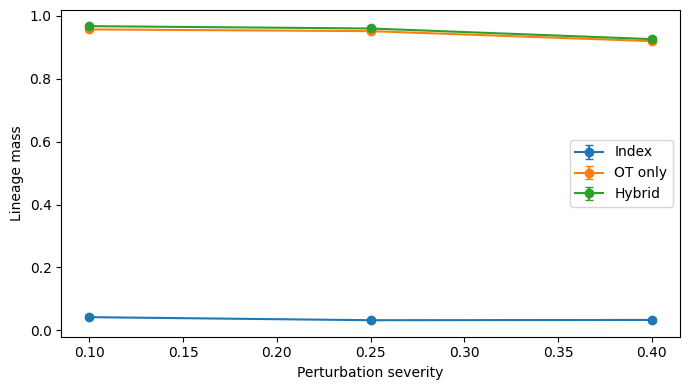

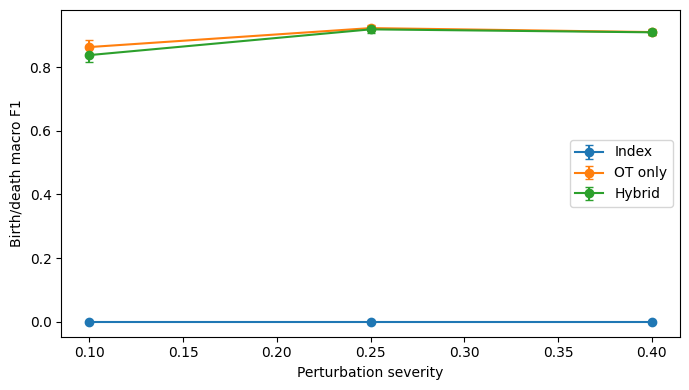

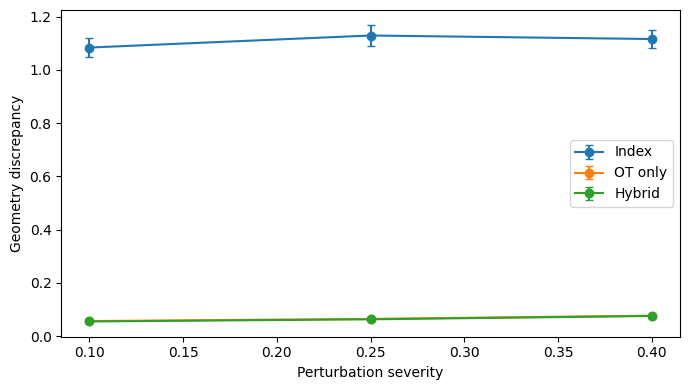

In [11]:
# ---------- Mixed-event severity plots with bootstrap 95% CIs ----------
def plot_mixed_metric(metric, ylabel, filename):
    plt.figure(figsize=(7, 4))

    for method_idx, method in enumerate(METHODS):
        xs, ys, lo_err, hi_err = [], [], [], []

        for severity_idx, severity in enumerate(CFG.severities):
            vals = res.loc[
                (res.kind == 'mixed')
                & (res.method == method)
                & (res.severity == severity),
                metric,
            ].values

            rng = np.random.default_rng(
                CFG.bootstrap_seed + 100 * method_idx + severity_idx
            )
            mean, lo, hi = bootstrap_mean_ci(
                vals, rng, CFG.bootstrap_samples
            )

            xs.append(severity)
            ys.append(mean)
            lo_err.append(mean - lo)
            hi_err.append(hi - mean)

        plt.errorbar(
            xs, ys,
            yerr=np.vstack([lo_err, hi_err]),
            marker='o',
            capsize=3,
            label=method,
        )

    plt.xlabel('Perturbation severity')
    plt.ylabel(ylabel)
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULT_DIR / filename, dpi=180)
    plt.show()

plot_mixed_metric(
    'lineage_mass',
    'Lineage mass',
    'mixed_lineage_mass_vs_severity.png',
)
plot_mixed_metric(
    'event_f1_macro',
    'Birth/death macro F1',
    'mixed_event_f1_vs_severity.png',
)
plot_mixed_metric(
    'geometry_discrepancy',
    'Geometry discrepancy',
    'mixed_geometry_discrepancy_vs_severity.png',
)


lineage_mass  event_f1_macro  geometry_discrepancy
id_dropout_rate method                                                     
0.00            Hybrid       0.959877        0.918495              0.063491
                OT only      0.951482        0.922440              0.065024
0.10            Hybrid       0.959157        0.918495              0.063607
                OT only      0.951482        0.922440              0.065024
0.25            Hybrid       0.958383        0.918987              0.063762
                OT only      0.951482        0.922440              0.065024
0.50            Hybrid       0.956491        0.921922              0.064086
                OT only      0.951482        0.922440              0.065024

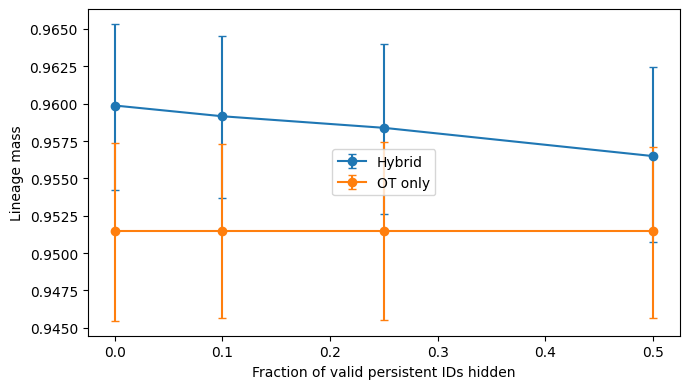

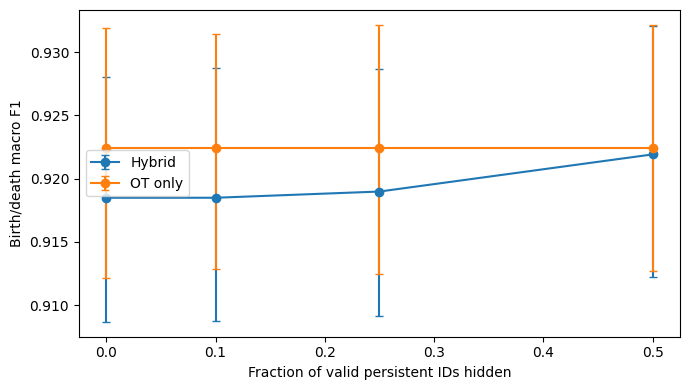

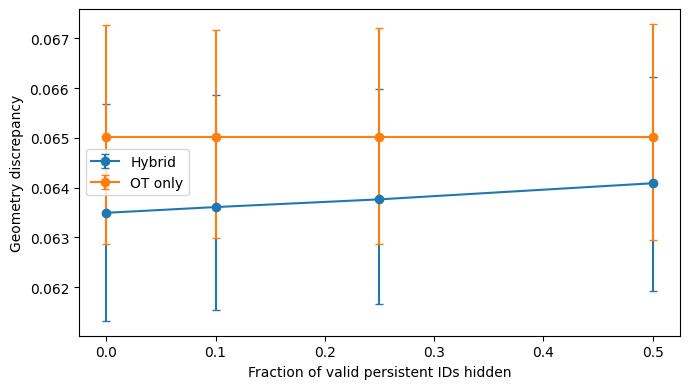

In [12]:
# ---------- Persistent-ID dropout stress test ----------
# Appendix experiment: hide reliable IDs and verify that Hybrid falls back
# toward OT-only rather than failing catastrophically.
drop_rows = []

if CFG.id_dropout_severity not in CFG.severities:
    raise ValueError(
        'id_dropout_severity must be one of CFG.severities for the paired stress test.'
    )

severity_idx = list(CFG.severities).index(CFG.id_dropout_severity)
kind_idx = KINDS.index(CFG.id_dropout_kind)

for seed in CFG.seeds:
    for trial in range(CFG.trials_per_setting):
        src = make_source(
            source_seed(seed, severity_idx, trial),
            CFG,
        )

        tgt_rng = seed_trial_rng(
            seed, severity_idx, trial, kind_idx, stream=0
        )
        tgt = perturb_source(
            src,
            CFG.id_dropout_kind,
            CFG.id_dropout_severity,
            tgt_rng,
            CFG,
        )

        # OT ignores persistent IDs, so it is a fixed fallback reference.
        P_ot = ot_plan(src, tgt, CFG)
        m_ot = metrics(src, tgt, P_ot)

        for rate_idx, rate in enumerate(CFG.id_dropout_rates):
            id_rng = seed_trial_rng(
                seed, severity_idx, trial, kind_idx,
                stream=100 + rate_idx,
            )
            tgt_hidden = hide_persistent_ids(tgt, rate, id_rng)

            P_h = hybrid_plan(src, tgt_hidden, CFG)
            m_h = metrics(src, tgt_hidden, P_h)

            drop_rows.append({
                'seed': seed,
                'trial': trial,
                'id_dropout_rate': rate,
                'method': 'Hybrid',
                **m_h,
            })

            # Repeat the same OT reference for direct plotting/comparison.
            drop_rows.append({
                'seed': seed,
                'trial': trial,
                'id_dropout_rate': rate,
                'method': 'OT only',
                **m_ot,
            })

id_dropout_df = pd.DataFrame(drop_rows)
id_dropout_df.to_csv(RESULT_DIR / 'id_dropout_trials.csv', index=False)

id_dropout_seed = (
    id_dropout_df
    .groupby(['seed', 'id_dropout_rate', 'method'])[CORE_METRICS]
    .mean(numeric_only=True)
    .reset_index()
)
id_dropout_summary = (
    id_dropout_seed
    .groupby(['id_dropout_rate', 'method'])[CORE_METRICS]
    .agg(['mean', 'std'])
    .reset_index()
)
id_dropout_summary.to_csv(
    RESULT_DIR / 'id_dropout_summary_mean_std.csv',
    index=False,
)

display(
    id_dropout_df
    .groupby(['id_dropout_rate', 'method'])[
        ['lineage_mass', 'event_f1_macro', 'geometry_discrepancy']
    ]
    .mean()
)

def plot_id_dropout(metric, ylabel, filename):
    plt.figure(figsize=(7, 4))

    for method_idx, method in enumerate(['Hybrid', 'OT only']):
        xs, ys, lo_err, hi_err = [], [], [], []

        for rate_idx, rate in enumerate(CFG.id_dropout_rates):
            vals = id_dropout_df.loc[
                (id_dropout_df.id_dropout_rate == rate)
                & (id_dropout_df.method == method),
                metric,
            ].values

            rng = np.random.default_rng(
                CFG.bootstrap_seed + 500 + 100 * method_idx + rate_idx
            )
            mean, lo, hi = bootstrap_mean_ci(
                vals, rng, CFG.bootstrap_samples
            )

            xs.append(rate)
            ys.append(mean)
            lo_err.append(mean - lo)
            hi_err.append(hi - mean)

        plt.errorbar(
            xs, ys,
            yerr=np.vstack([lo_err, hi_err]),
            marker='o',
            capsize=3,
            label=method,
        )

    plt.xlabel('Fraction of valid persistent IDs hidden')
    plt.ylabel(ylabel)
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULT_DIR / filename, dpi=180)
    plt.show()

plot_id_dropout(
    'lineage_mass',
    'Lineage mass',
    'id_dropout_lineage_mass.png',
)
plot_id_dropout(
    'event_f1_macro',
    'Birth/death macro F1',
    'id_dropout_event_f1.png',
)
plot_id_dropout(
    'geometry_discrepancy',
    'Geometry discrepancy',
    'id_dropout_geometry_discrepancy.png',
)


In [13]:
# ---------- Sanity / fairness checks ----------
# 1) Pure permutation preserves lineage; Hybrid should recover it exactly
# when persistent IDs are available.
src = make_source(123, CFG)
tgt = perturb_source(
    src,
    'permutation',
    0.25,
    np.random.default_rng(5),
    CFG,
)
P_h = hybrid_plan(src, tgt, CFG)
m_h = metrics(src, tgt, P_h)
assert m_h['lineage_mass'] > 0.999, m_h

# 2) Full OT uses count-aware unit marginals for every real primitive.
P_o = ot_plan(src, tgt, CFG)
ns, nt = len(src['mu']), len(tgt['mu'])
assert np.isfinite(P_o).all() and (P_o >= 0).all()
assert np.allclose(P_o[:ns, :].sum(axis=1), 1.0, atol=5e-4)
assert np.allclose(P_o[:, :nt].sum(axis=0), 1.0, atol=5e-4)
assert np.isclose(P_o[-1, :].sum(), nt, atol=5e-4)
assert np.isclose(P_o[:, -1].sum(), ns, atol=5e-4)

# 3) Hybrid hard matches and residual OT are on the same unit-mass scale:
# every real source row and real target column carries one unit.
assert np.allclose(P_h[:ns, :].sum(axis=1), 1.0, atol=5e-4)
assert np.allclose(P_h[:, :nt].sum(axis=0), 1.0, atol=5e-4)
hard_vals = P_h[:ns, :nt][P_h[:ns, :nt] > 0.999999]
assert len(hard_vals) > 0
assert np.allclose(hard_vals, 1.0, atol=1e-6)

# 4) Birth/death metrics are N/A when no such event exists.
assert np.isnan(m_h['birth_f1'])
assert np.isnan(m_h['death_f1'])
assert np.isnan(m_h['event_f1_macro'])

# 5) Hiding IDs does not alter geometry or lineage; it only removes
# identity information available to Hybrid.
tgt_hidden = hide_persistent_ids(
    tgt, 0.5, np.random.default_rng(99)
)
assert np.allclose(tgt_hidden['mu'], tgt['mu'])
assert np.allclose(tgt_hidden['logscale'], tgt['logscale'])
assert all(
    a == b
    for a, b in zip(tgt_hidden['lineage'], tgt['lineage'])
)
assert np.sum(tgt_hidden['slot_id'] >= 0) < np.sum(tgt['slot_id'] >= 0)

print('All Exp3-v2 sanity/fairness checks passed.')
print('Hybrid permutation lineage mass:', m_h['lineage_mass'])
print('Count-aware OT total mass:', P_o.sum(), '= ns + nt =', ns + nt)


All Exp3-v2 sanity/fairness checks passed.
Hybrid permutation lineage mass: 0.9999999999999584
Count-aware OT total mass: 54.00000000000001 = ns + nt = 54


In [14]:
# ---------- Package all results ----------
zip_path = shutil.make_archive(
    str(BASE_DIR / '4dgs_jepa_exp3_results_v2'),
    'zip',
    root_dir=RESULT_DIR,
)
print('Created:', zip_path)

try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print('Local ZIP path:', zip_path)


Created: /content/4dgs_jepa_exp3_results_v2.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>